# 06_06 Multiple Testing: Bonferroni, Holm and Benjamini-Hochberg

**Learning objectives**
- Explain why running many tests inflates false positives, and define the **family-wise error rate (FWER)** and the **false discovery rate (FDR)**.
- Apply the **Bonferroni**, **Holm** and **Benjamini-Hochberg (BH)** procedures by hand, and compute **adjusted p-values**.
- Use **Tukey's HSD** for all pairwise comparisons after an ANOVA.
- Choose between **controlling any false positive** (FWER) and **controlling the share of false discoveries** (FDR), and check each rule by simulation.

**Prerequisites:** [06_03 Hypothesis testing](06_03_hypothesis_testing_core.ipynb) (Example 3: twenty tests on noise), [06_04 The common tests](06_04_common_tests.ipynb), [05_05 Concentration inequalities](../../module_05_sampling/notebooks/05_05_concentration_inequalities.ipynb) (union bound), [0a_03 The rules of probability](../../module_0a_basics/notebooks/0a_03_probability_rules.ipynb).

## 1. Setup

All imports in one cell; the generator is seeded so every run gives the same numbers.

In [1]:
import sys
sys.path.append("../..")  # repo root, so common.style can be imported
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.graph_objects as go
from scipy import stats
from common.style import apply_style, MAIN, SIM, HIGHLIGHT, NEUTRAL, COLORS

apply_style()
rng = np.random.default_rng(42)  # fixed seed so every run gives the same numbers

import math, itertools

## 2. Prerequisite recap

- A level-$\alpha$ test makes a **false positive** with probability $\alpha$ when $H_0$ is true; under $H_0$ the p-value is **Uniform(0,1)** (06_03).
- For $m$ independent tests the chance of at least one false positive is $1-(1-\alpha)^m$ (0a_03).
- The **union bound:** $P(\bigcup A_i)\le\sum P(A_i)$ (05_05).
- The **ANOVA** $F$ test answers "is there any difference among $k$ groups?" but not "which ones?" (06_04).

## 3. Intuition and story

One test at 5 % is a fair bet. Twenty tests at 5 % on pure noise give a false "discovery" with probability 64 % (06_03). A dashboard with 50 metrics, a genomic screen with 20,000 genes, a feature-selection run with thousands of candidate features: the more questions we ask the more *apparently significant* answers appear by luck. We must **raise the bar** as the number of tests grows.

There are two sensible goals:

- **Family-wise error rate (FWER):** the probability of making **at least one** false discovery. A strict goal for a small number of important claims (a drug approval). Methods: **Bonferroni**, **Holm**.
- **False discovery rate (FDR):** the expected **proportion of false discoveries among the discoveries**. A lenient goal that tolerates a few false leads in exchange for far more power; the right one for screening many candidates where findings will be followed up. Method: **Benjamini-Hochberg**.

Think of a hit list: FWER says "I want the whole list to be clean"; FDR says "I accept that about 5 % of the list may be wrong".

## 4. Formal definitions

With $m$ tests, $m_0$ true nulls, $R$ rejections and $V$ false rejections among them (so $R-V$ true discoveries):

| | $H_0$ true | $H_0$ false | total |
|---|---|---|---|
| rejected | $V$ | $S$ | $R$ |
| not rejected | $U$ | $T$ | $m-R$ |
| | $m_0$ | $m-m_0$ | $m$ |

**FWER** $=P(V\ge1)$. **FDR** $=E\big[V/\max(R,1)\big]$. **Power** (average) $=E[S]/(m-m_0)$.

| Procedure | Rule (sorted p-values $p_{(1)}\le\dots\le p_{(m)}$, level $\alpha$) | Controls |
|---|---|---|
| **Bonferroni** | reject $H_i$ if $p_i\le\alpha/m$ | FWER (any dependence) |
| **Sidak** | reject if $p_i\le1-(1-\alpha)^{1/m}$ | FWER (independent tests) |
| **Holm** (step-down) | find the smallest $k$ with $p_{(k)}>\dfrac\alpha{m-k+1}$; reject $H_{(1)},\dots,H_{(k-1)}$ | FWER (any dependence), uniformly more powerful than Bonferroni |
| **Benjamini-Hochberg** (step-up) | find the largest $k$ with $p_{(k)}\le\dfrac km\alpha$; reject $H_{(1)},\dots,H_{(k)}$ | FDR $\le\frac{m_0}m\alpha$ (independent or positively dependent tests) |
| **Tukey HSD** | all pairwise differences of $k$ group means using the studentised range | FWER for pairwise comparisons |

**Adjusted p-values:** Bonferroni $\tilde p_i=\min(1,mp_i)$; BH $\tilde p_{(i)}=\min_{j\ge i}\big(\tfrac mjp_{(j)}\big)$ (also called the $q$-value): reject when the adjusted p-value is $\le\alpha$.

## 5. Derivations

### 5.1 Bonferroni from the union bound
Let $A_i$ be the event "test $i$ is a false positive". If every true null is tested at level $\alpha/m$, then $P(V\ge1)=P\big(\bigcup_{i\in H_0}A_i\big)\le\sum_{i\in H_0}\frac\alpha m=\frac{m_0}m\alpha\le\alpha$. No independence is needed. **In plain words.** Split the 5 % false-alarm budget evenly among the tests; the budgets add up to at most 5 % whatever the dependence.

### 5.2 Holm is a sharper Bonferroni
Sort the p-values. Test the smallest at $\alpha/m$; if it is rejected, only $m-1$ hypotheses remain, so test the next at $\alpha/(m-1)$; and so on until the first failure, then stop. The family-wise error is still $\le\alpha$ (the first false rejection must happen at a step where the threshold is at most $\alpha/m_0$...). **In plain words.** Once a hypothesis is rejected it no longer needs a share of the error budget, so the remaining tests can be tested at a more generous level.

### 5.3 The Benjamini-Hochberg step-up rule
Plot the sorted p-values against $k$ and draw the line of slope $\alpha/m$ through the origin: BH rejects everything up to the **last** point that is on or below the line. **In plain words.** If $k$ hypotheses are rejected, the threshold for the largest rejected p-value is $k\alpha/m$: the more discoveries there are, the more generous the cut, which is why BH has so much more power than Bonferroni when there are many real effects. Benjamini and Hochberg proved $\mathrm{FDR}\le\frac{m_0}m\alpha$ for independent tests.

### 5.4 Why FDR control is lenient but meaningful
If all $m$ nulls are true, BH rejects something with probability $\le\alpha$ (it controls the FWER in the *complete null*); if many effects are real, $m_0/m$ is small and the actual FDR is below $\alpha$. **In plain words.** BH is automatically strict when there is nothing to find and generous when there is a lot.

### 5.5 Expected number of false positives without correction
With $m_0$ true nulls tested at $\alpha$, $E[V]=m_0\alpha$ (the mean of a Binomial($m_0,\alpha$)). For $m=1000$ tests and 900 true nulls this is **45** false discoveries, against maybe 100 real ones: nearly one third of the discoveries are false. **In plain words.** Without correction the false discovery share can be enormous when most hypotheses are null.

### 5.6 Tukey's HSD
For $k$ groups of size $n$ and pooled variance $s^2$, two means differ significantly when $|\bar x_i-\bar x_j|>q_{\alpha,k,N-k}\,s/\sqrt n$, where $q$ is a quantile of the **studentised range** (the distribution of $\max-\min$ of $k$ standardised means). **In plain words.** It compares each pair to the *largest* difference that chance alone would produce among $k$ groups, which automatically accounts for all $\binom k2$ comparisons.

## 6. Properties and relationships

- **FWER is stricter than FDR:** $\mathrm{FDR}\le\mathrm{FWER}$ always, and controlling the FWER controls the FDR. Choose FWER when a *single* false claim is costly (confirmatory trial), FDR for exploratory screens.
- **Power cost:** Bonferroni loses power quickly with $m$ (the threshold $\alpha/m$ shrinks); Holm is never worse; BH is far more powerful when many effects are real.
- **Dependence:** Bonferroni and Holm hold under any dependence; BH needs independence or positive dependence (the Benjamini-Yekutieli version covers arbitrary dependence at the cost of a $\sum1/k$ factor).
- **Pre-registration beats correction:** a single pre-specified primary hypothesis needs no correction; secondary hypotheses can be tested in a fixed order (hierarchical testing).
- **Link to ML and AI:** feature screening on thousands of candidates, comparing many models or hyperparameter settings on the same test set (the winner's curse, 05_07: the best of $K$ scores is biased upward), monitoring dozens of fairness or drift metrics, and a dashboard of A/B metrics all need multiplicity control.

## 7. 2D visuals

### 7.1 How fast the false-positive chance grows
$P(\text{at least one false positive})=1-(1-\alpha)^m$ for the uncorrected test, against the Bonferroni-corrected test (which stays at about $\alpha$): 100 tests give 99.4 % without correction.

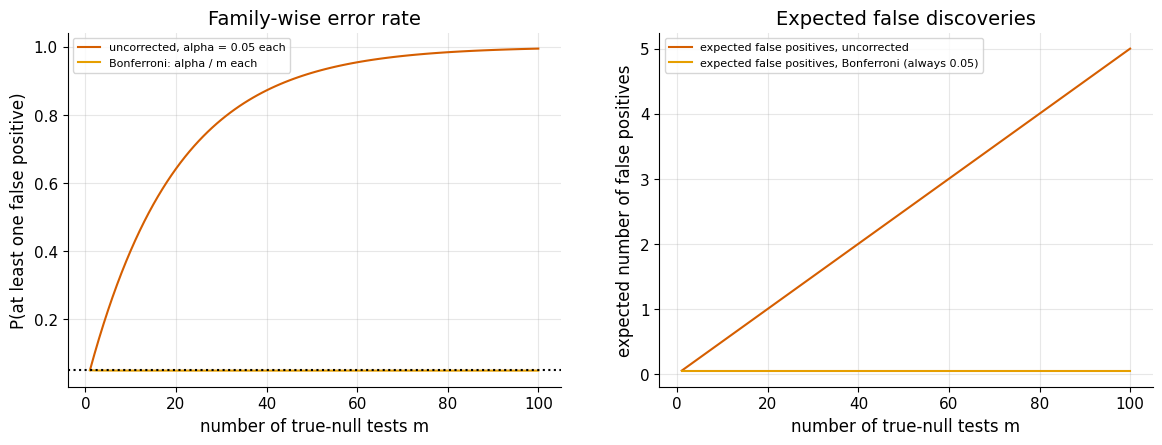

{1: 0.05, 5: 0.2262, 10: 0.4013, 20: 0.6415, 50: 0.9231, 100: 0.9941}


In [2]:
ms = np.arange(1, 101)
fig, axes = plt.subplots(1, 2, figsize=(14, 4.6))
axes[0].plot(ms, 1 - 0.95 ** ms, color=HIGHLIGHT, label="uncorrected, alpha = 0.05 each"); axes[0].plot(ms, 1 - (1 - 0.05 / ms) ** ms, color=SIM, label="Bonferroni: alpha / m each"); axes[0].axhline(0.05, color="black", linestyle=":")
axes[0].set_xlabel("number of true-null tests m"); axes[0].set_ylabel("P(at least one false positive)"); axes[0].set_title("Family-wise error rate"); axes[0].legend(fontsize=8)
axes[1].plot(ms, ms * 0.05, color=HIGHLIGHT, label="expected false positives, uncorrected"); axes[1].plot(ms, ms * (0.05 / ms), color=SIM, label="expected false positives, Bonferroni (always 0.05)"); axes[1].set_xlabel("number of true-null tests m"); axes[1].set_ylabel("expected number of false positives"); axes[1].set_title("Expected false discoveries"); axes[1].legend(fontsize=8)
plt.show()
print({m_: round(1 - 0.95 ** m_, 4) for m_ in (1, 5, 10, 20, 50, 100)})
assert abs((1 - 0.95 ** 20) - 0.6415) < 1e-4

### 7.2 The Benjamini-Hochberg picture
The 20 sorted p-values of the main example against their rank. The Bonferroni threshold is the flat line $\alpha/m$, the Holm thresholds a slightly rising staircase and the BH threshold the straight line $k\alpha/m$: BH rejects up to the last point under the line.

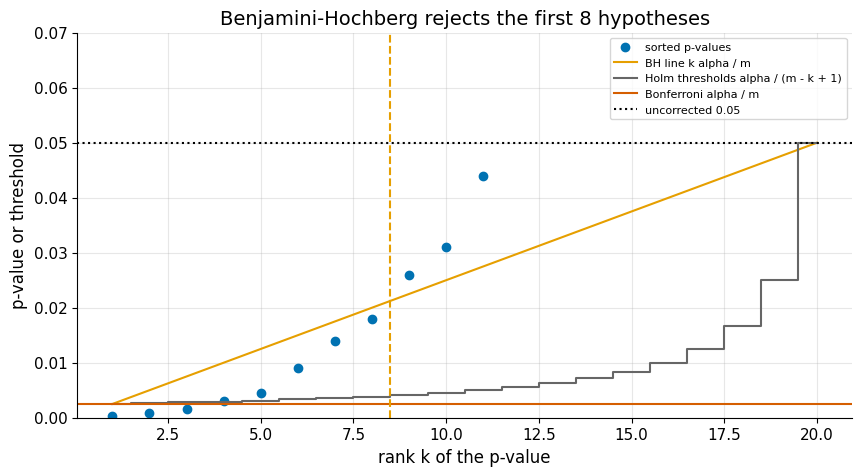

In [3]:
pvals = np.array([0.0004, 0.0009, 0.0015, 0.003, 0.0045, 0.009, 0.014, 0.018, 0.026, 0.031, 0.044, 0.079, 0.15, 0.22, 0.33, 0.41, 0.52, 0.67, 0.80, 0.93])
m = pvals.size; k = np.arange(1, m + 1)
bh_line = k * 0.05 / m; holm_line = 0.05 / (m - k + 1)
k_bh = np.max(np.where(pvals <= bh_line)[0]) + 1 if np.any(pvals <= bh_line) else 0
fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(k, pvals, "o", color=MAIN, label="sorted p-values"); ax.plot(k, bh_line, color=SIM, label="BH line k alpha / m"); ax.step(k, holm_line, where="mid", color=NEUTRAL, label="Holm thresholds alpha / (m - k + 1)"); ax.axhline(0.05 / m, color=HIGHLIGHT, label="Bonferroni alpha / m"); ax.axhline(0.05, color="black", linestyle=":", label="uncorrected 0.05")
ax.axvline(k_bh + 0.5, color=SIM, linestyle="--"); ax.set_ylim(0, 0.07); ax.set_xlabel("rank k of the p-value"); ax.set_ylabel("p-value or threshold"); ax.set_title(f"Benjamini-Hochberg rejects the first {k_bh} hypotheses"); ax.legend(fontsize=8)
plt.show()
assert k_bh == 8

### 7.3 Power against FDR for the three rules
Simulation of 1,000 tests with 100 real effects ($z$-shift 3): the uncorrected rule finds the most real effects but at a huge false-discovery share, Bonferroni is clean but misses most effects, BH is the compromise.

                    FDR (false share of discoveries)  power   FWER
uncorrected                                    0.328  0.914  1.000
Bonferroni                                     0.003  0.190  0.047
Holm                                           0.003  0.192  0.047
Benjamini-Hochberg                             0.045  0.612  0.930


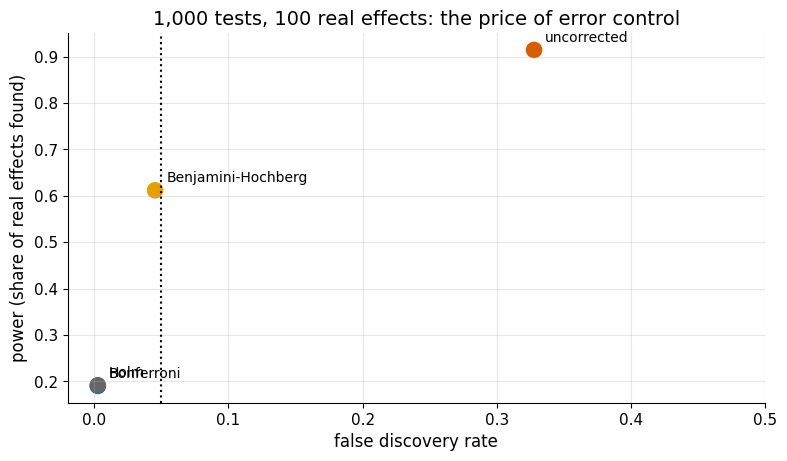

In [4]:
def simulate(rule, m=1000, m1=100, shift=3.0, reps=300, alpha=0.05, seed=0):
    g = np.random.default_rng(seed); fdp, power, fw = [], [], []
    for _ in range(reps):
        z = g.normal(size=m); z[:m1] += shift; p = stats.norm.sf(z)                           # one-sided p-values; the first m1 hypotheses are truly non-null
        rej = rule(p, alpha); V = rej[m1:].sum(); S = rej[:m1].sum(); R = V + S
        fdp.append(V / max(R, 1)); power.append(S / m1); fw.append(V >= 1)
    return np.mean(fdp), np.mean(power), np.mean(fw)
def r_none(p, a): return p <= a
def r_bonf(p, a): return p <= a / p.size
def r_holm(p, a):
    o = np.argsort(p); ok = p[o] <= a / (p.size - np.arange(p.size)); rej = np.zeros(p.size, bool); first_fail = np.argmin(ok) if not ok.all() else p.size; rej[o[:first_fail]] = True; return rej
def r_bh(p, a): return stats.false_discovery_control(p, method="bh") <= a
rows = {name: simulate(rule) for name, rule in [("uncorrected", r_none), ("Bonferroni", r_bonf), ("Holm", r_holm), ("Benjamini-Hochberg", r_bh)]}
res = pd.DataFrame(rows, index=["FDR (false share of discoveries)", "power", "FWER"]).T; print(res.round(3).to_string())
fig, ax = plt.subplots(figsize=(9, 4.8))
ax.scatter(res["FDR (false share of discoveries)"], res["power"], s=120, color=[HIGHLIGHT, MAIN, NEUTRAL, SIM])
for name, row in res.iterrows(): ax.annotate(name, (row.iloc[0], row.iloc[1]), textcoords="offset points", xytext=(8, 6))
ax.axvline(0.05, color="black", linestyle=":"); ax.set_xlabel("false discovery rate"); ax.set_ylabel("power (share of real effects found)"); ax.set_title("1,000 tests, 100 real effects: the price of error control"); ax.set_xlim(-0.02, 0.5)
plt.show()
assert res.loc["uncorrected", "FDR (false share of discoveries)"] > 0.25 and res.loc["Bonferroni", "FWER"] < 0.09 and res.loc["Benjamini-Hochberg", "FDR (false share of discoveries)"] < 0.06 and res.loc["Benjamini-Hochberg", "power"] > res.loc["Bonferroni", "power"]

### 7.4 Pairwise comparisons of four groups: the interval picture
Simultaneous 95 % intervals (Tukey) for the six pairwise differences of four group means are wider than the separate intervals; those not containing 0 are significant. A difference that looks significant on its own can fail after the correction.

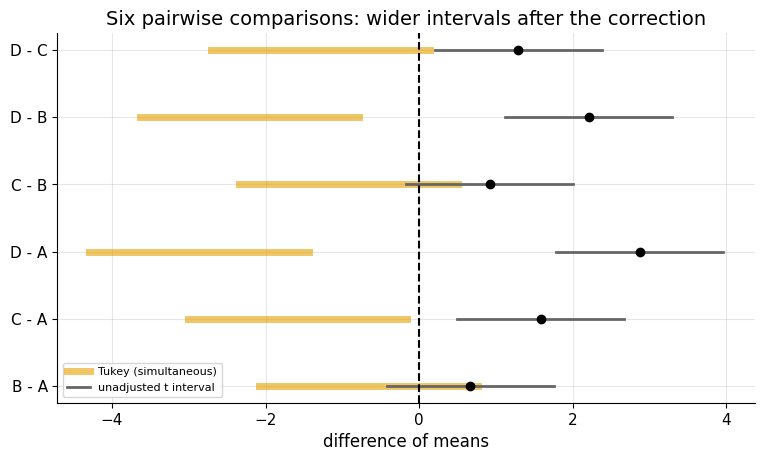

Tukey's HSD Pairwise Group Comparisons (95.0% Confidence Interval)
Comparison  Statistic  p-value  Lower CI  Upper CI
 (0 - 1)     -0.662     0.626    -2.091     0.767
 (0 - 2)     -1.582     0.024    -3.011    -0.153
 (0 - 3)     -2.870     0.000    -4.299    -1.441
 (1 - 0)      0.662     0.626    -0.767     2.091
 (1 - 2)     -0.920     0.342    -2.350     0.509
 (1 - 3)     -2.208     0.001    -3.637    -0.779
 (2 - 0)      1.582     0.024     0.153     3.011
 (2 - 1)      0.920     0.342    -0.509     2.350
 (2 - 3)     -1.288     0.094    -2.717     0.142
 (3 - 0)      2.870     0.000     1.441     4.299
 (3 - 1)      2.208     0.001     0.779     3.637
 (3 - 2)      1.288     0.094    -0.142     2.717



In [5]:
means_g = np.array([10.0, 10.4, 11.2, 12.0]); sd_g, n_g = 2.5, 40; g4 = np.random.default_rng(4)
dat = [g4.normal(m_, sd_g, n_g) for m_ in means_g]; tk = stats.tukey_hsd(*dat); ci = tk.confidence_interval(0.95)
pairs = list(itertools.combinations(range(4), 2)); sp = np.sqrt(np.mean([d.var(ddof=1) for d in dat])); se = sp * np.sqrt(2 / n_g); tc = stats.t.ppf(0.975, 4 * n_g - 4)
fig, ax = plt.subplots(figsize=(9, 4.8))
for y, (i, j) in enumerate(pairs):
    d = dat[j].mean() - dat[i].mean(); ax.plot([ci.low[i, j], ci.high[i, j]], [y, y], color=SIM, linewidth=5, alpha=0.6, label="Tukey (simultaneous)" if y == 0 else ""); ax.plot([d - tc * se, d + tc * se], [y, y], color=NEUTRAL, linewidth=2, label="unadjusted t interval" if y == 0 else ""); ax.plot(d, y, "ko")
ax.axvline(0, color="black", linestyle="--"); ax.set_yticks(range(6)); ax.set_yticklabels([f"{'ABCD'[j]} - {'ABCD'[i]}" for i, j in pairs]); ax.set_xlabel("difference of means"); ax.set_title("Six pairwise comparisons: wider intervals after the correction"); ax.legend(fontsize=8)
plt.show()
print(tk)

## 8. 3D visuals

### 8.1 Static: the family-wise error rate over (number of tests, level)
$\mathrm{FWER}=1-(1-\alpha)^m$ without correction. The surface shows how quickly it saturates at 1: already at $\alpha=0.05$ and $m=50$ the chance of at least one false positive is 92 %. The Bonferroni-corrected surface would be a flat sheet at height $\alpha$.

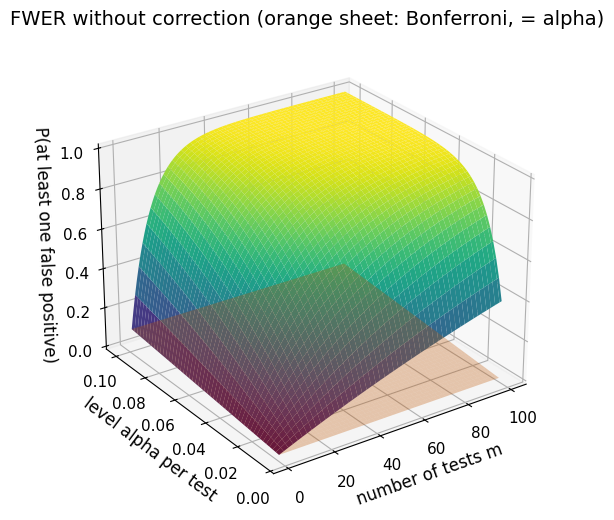

at alpha = 0.05: m = 14 gives 0.512 | m = 50 gives 0.923


In [6]:
m_ax = np.arange(1, 101); a_ax = np.linspace(0.005, 0.10, 50); Mg, Ag = np.meshgrid(m_ax, a_ax)
FW = 1 - (1 - Ag) ** Mg
fig = plt.figure(figsize=(8.8, 6.2))
ax = fig.add_subplot(projection="3d")
ax.plot_surface(Mg, Ag, FW, cmap="viridis", edgecolor="none"); ax.plot_surface(Mg, Ag, Ag, color=HIGHLIGHT, alpha=0.3, edgecolor="none")
ax.set_xlabel("number of tests m"); ax.set_ylabel("level alpha per test"); ax.set_zlabel("P(at least one false positive)"); ax.set_title("FWER without correction (orange sheet: Bonferroni, = alpha)"); ax.view_init(elev=26, azim=-125)
plt.show()
print("at alpha = 0.05: m = 14 gives", round(1 - 0.95 ** 14, 3), "| m = 50 gives", round(1 - 0.95 ** 50, 3))

### 8.2 Interactive Plotly version of 8.1
Hover to read the family-wise error rate.

In [7]:
fig = go.Figure(go.Surface(x=m_ax, y=a_ax, z=FW, colorscale="Viridis"))
fig.update_layout(title="FWER = 1 - (1 - alpha)^m", width=760, height=560, scene=dict(xaxis_title="m", yaxis_title="alpha", zaxis_title="FWER"))
fig.show()

### 8.3 Static: power of Benjamini-Hochberg over (share of real effects, effect size)
Simulated power of BH at FDR 5 % for 500 tests: it grows with the effect size and, interestingly, with the share of real effects (the BH line tilts upwards when there are many discoveries). The simulated FDR stays below 5 %.

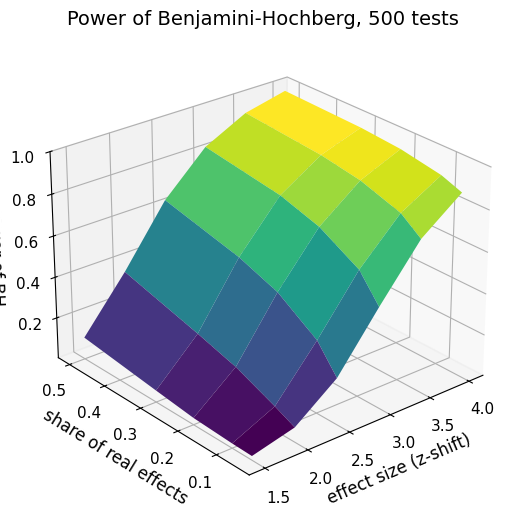

average simulated FDR over the grid: 0.040, largest 0.069 (target 0.05 x (1 - share of real effects))


In [8]:
fr = np.array([0.05, 0.1, 0.2, 0.3, 0.5]); sh = np.array([1.5, 2.0, 2.5, 3.0, 3.5, 4.0]); PWb = np.zeros((fr.size, sh.size)); FDb = np.zeros_like(PWb)
for i, f_ in enumerate(fr):
    for j, s_ in enumerate(sh):
        fd, pw_, _ = simulate(r_bh, m=500, m1=int(500 * f_), shift=s_, reps=120, seed=i * 10 + j); PWb[i, j], FDb[i, j] = pw_, fd
Sg, Fg = np.meshgrid(sh, fr)
fig = plt.figure(figsize=(8.8, 6.2))
ax = fig.add_subplot(projection="3d")
ax.plot_surface(Sg, Fg, PWb, cmap="viridis", edgecolor="none"); ax.set_xlabel("effect size (z-shift)"); ax.set_ylabel("share of real effects"); ax.set_zlabel("power of BH"); ax.set_title("Power of Benjamini-Hochberg, 500 tests"); ax.view_init(elev=26, azim=-130)
plt.show()
print(f"average simulated FDR over the grid: {FDb.mean():.3f}, largest {FDb.max():.3f} (target 0.05 x (1 - share of real effects))")
assert FDb.mean() < 0.05 and FDb.max() < 0.09

## 9. Simulation vs theory

### 9.1 FWER and FDR when everything is null, and when 10 % is real
(a) All 1,000 nulls true: the chance of any rejection should be 5 % for Bonferroni, Holm and BH alike. (b) With 10 % real effects the BH false discovery rate should be about $\frac{m_0}m\alpha=0.9\times0.05=0.045$.

In [9]:
def all_null(rule, reps=1500, m=1000, seed=3):
    g = np.random.default_rng(seed); return np.mean([rule(g.uniform(size=m), 0.05).any() for _ in range(reps)])
fw_null = {name: all_null(rule) for name, rule in [("uncorrected", r_none), ("Bonferroni", r_bonf), ("Holm", r_holm), ("Benjamini-Hochberg", r_bh)]}
fdr_mix = simulate(r_bh, m=1000, m1=100, shift=3.0, reps=400)[0]
print("(a) P(any rejection) when all 1,000 nulls are true:", {k: round(v, 3) for k, v in fw_null.items()})
print(f"(b) BH false discovery rate with 10 % real effects: {fdr_mix:.4f} (theory <= {0.9 * 0.05:.3f})")
assert fw_null["uncorrected"] > 0.99 and all(abs(fw_null[k] - 0.05) < 0.025 for k in ("Bonferroni", "Holm", "Benjamini-Hochberg")) and fdr_mix < 0.05

(a) P(any rejection) when all 1,000 nulls are true: {'uncorrected': np.float64(1.0), 'Bonferroni': np.float64(0.047), 'Holm': np.float64(0.047), 'Benjamini-Hochberg': np.float64(0.048)}
(b) BH false discovery rate with 10 % real effects: 0.0451 (theory <= 0.045)


### 9.2 BH under dependence
Positively correlated tests (a common factor of correlation 0.5 between the $z$-scores) keep the BH false discovery rate below the nominal 5 %, as the theory for positive dependence promises.

In [10]:
def simulate_corr(rho, m=1000, m1=100, shift=3.0, reps=300, seed=5):
    g = np.random.default_rng(seed); fdp = []
    for _ in range(reps):
        z = np.sqrt(rho) * g.normal() + np.sqrt(1 - rho) * g.normal(size=m); z[:m1] += shift; rej = r_bh(stats.norm.sf(z), 0.05); R = rej.sum(); fdp.append(rej[m1:].sum() / max(R, 1))
    return np.mean(fdp)
print({rho: round(simulate_corr(rho), 4) for rho in (0.0, 0.3, 0.5)})
assert all(simulate_corr(r_, reps=150) < 0.065 for r_ in (0.0, 0.5))

{0.0: np.float64(0.0444), 0.3: np.float64(0.0373), 0.5: np.float64(0.0326)}


## 10. `scipy.stats` and NumPy cheat sheet for this lesson

In [11]:
print("Benjamini-Hochberg adjusted p-values: stats.false_discovery_control(p, method='bh') ->", np.round(stats.false_discovery_control(pvals)[:10], 4))
print("Benjamini-Yekutieli (arbitrary dependence): method='by' ->", np.round(stats.false_discovery_control(pvals, method='by')[:5], 4))
print("Bonferroni adjusted: np.minimum(1, m * p) ->", np.round(np.minimum(1, m * pvals)[:5], 4))
print("Tukey HSD: stats.tukey_hsd(g1, g2, g3, g4).pvalue ->\n", np.round(tk.pvalue, 4))
print("rejections: BH", int((stats.false_discovery_control(pvals) <= 0.05).sum()), "| Bonferroni", int((np.minimum(1, m * pvals) <= 0.05).sum()), "| uncorrected", int((pvals <= 0.05).sum()))
print("statsmodels (if installed): from statsmodels.stats.multitest import multipletests; multipletests(p, alpha=0.05, method='holm' or 'fdr_bh')")
print("Sidak threshold for m = 20:", round(1 - 0.95 ** (1 / 20), 5), "| Bonferroni 0.05 / 20 =", 0.05 / 20)

Benjamini-Hochberg adjusted p-values: stats.false_discovery_control(p, method='bh') -> [0.008  0.009  0.01   0.015  0.018  0.03   0.04   0.045  0.0578 0.062 ]
Benjamini-Yekutieli (arbitrary dependence): method='by' -> [0.0288 0.0324 0.036  0.054  0.0648]
Bonferroni adjusted: np.minimum(1, m * p) -> [0.008 0.018 0.03  0.06  0.09 ]
Tukey HSD: stats.tukey_hsd(g1, g2, g3, g4).pvalue ->
 [[1.000e+00 6.262e-01 2.360e-02 0.000e+00]
 [6.262e-01 1.000e+00 3.417e-01 5.000e-04]
 [2.360e-02 3.417e-01 1.000e+00 9.350e-02]
 [0.000e+00 5.000e-04 9.350e-02 1.000e+00]]
rejections: BH 8 | Bonferroni 3 | uncorrected 11
statsmodels (if installed): from statsmodels.stats.multitest import multipletests; multipletests(p, alpha=0.05, method='holm' or 'fdr_bh')
Sidak threshold for m = 20: 0.00256 | Bonferroni 0.05 / 20 = 0.0025


## 11. Real-world worked examples

---
### Example 1 (main): twenty metrics on an A/B test dashboard

**Scenario.** An A/B test reports 20 metrics (clicks, revenue, retention, latency, ...). The raw p-values, sorted, are **0.0004, 0.0009, 0.0015, 0.003, 0.0045, 0.009, 0.014, 0.018, 0.026, 0.031, 0.044, 0.079, 0.15, 0.22, 0.33, 0.41, 0.52, 0.67, 0.80, 0.93**. Which metrics changed at an overall level of 5 %?

**Questions**
1. How many metrics are "significant" with no correction?
2. How many does **Bonferroni** keep? And **Holm**?
3. How many does **Benjamini-Hochberg** keep? What are the adjusted p-values (q-values) of the first ten?
4. Which method would you use and why?

### 11.1 By hand
**Q1.** Uncorrected: the p-values below 0.05 are the first **11**.

**Q2.** Bonferroni threshold $0.05/20=0.0025$: only $0.0004,\,0.0009,\,0.0015$ pass: **3**. Holm thresholds $0.05/20=0.0025,\ 0.05/19=0.00263,\ 0.05/18=0.00278,\ 0.05/17=0.00294$: the first three pass, the fourth ($0.003>0.00294$) fails and the procedure stops: **3** as well.

**Q3.** BH thresholds $k\times0.05/20=0.0025k$: $k=8$: $0.018\le0.02$ ✓; $k=9$: $0.026>0.0225$ ✗; $k=10$: $0.031>0.025$ ✗; $k=11$: $0.044>0.0275$ ✗; so the largest $k$ is 8 and BH rejects the first **8** metrics. The adjusted p-value of the $k$-th is $\min_{j\ge k}20p_{(j)}/j$, e.g. the first is $20(0.0004)/1=0.008$ and the eighth is $20(0.018)/8=0.045$.

**Q4.** If one headline metric matters (revenue), use it as the single primary hypothesis (no correction). For a dashboard of exploratory metrics use BH and follow up the discoveries; use Holm if any false claim is costly.

In [12]:
bonf_rej = (pvals <= 0.05 / m).sum()
ok = pvals <= 0.05 / (m - np.arange(m)); holm_rej = m if ok.all() else int(np.argmin(ok))
q_bh = stats.false_discovery_control(pvals, method="bh"); bh_rej = int((q_bh <= 0.05).sum())
manual_q = np.minimum.accumulate((m * pvals / k)[::-1])[::-1]
print(f"Q1: uncorrected {(pvals <= 0.05).sum()} | Q2: Bonferroni {bonf_rej}, Holm {holm_rej} | Q3: BH {bh_rej}")
print("BH adjusted p-values of the first ten:", np.round(q_bh[:10], 4), "| manual formula:", np.round(manual_q[:10], 4))
print("Bonferroni adjusted p-values of the first five:", np.round(np.minimum(1, m * pvals[:5]), 4))

Q1: uncorrected 11 | Q2: Bonferroni 3, Holm 3 | Q3: BH 8
BH adjusted p-values of the first ten: [0.008  0.009  0.01   0.015  0.018  0.03   0.04   0.045  0.0578 0.062 ] | manual formula: [0.008  0.009  0.01   0.015  0.018  0.03   0.04   0.045  0.0578 0.062 ]
Bonferroni adjusted p-values of the first five: [0.008 0.018 0.03  0.06  0.09 ]


### 11.2 In code with `scipy`, and the asserts

In [13]:
assert (pvals <= 0.05).sum() == 11 and bonf_rej == 3 and holm_rej == 3 and bh_rej == 8
assert np.allclose(q_bh, manual_q) and abs(q_bh[0] - 0.008) < 1e-9 and abs(q_bh[7] - 0.045) < 1e-9
assert (q_bh <= 0.05).sum() == k_bh                                                    # same answer as the step-up rule of 7.2
print("all checks passed")

all checks passed


### 11.3 Verify by simulation
Take a dashboard of 20 metrics where 5 are truly affected (a $z$-shift of 3.2) and 15 are not. Compare the rules by the average number of false and true discoveries over 20,000 dashboards.

In [14]:
sg = np.random.default_rng(31); R = 20_000; z = sg.normal(size=(R, 20)); z[:, :5] += 3.2; P = stats.norm.sf(z)
out = {}
for name, rule in [("uncorrected", r_none), ("Bonferroni", r_bonf), ("Holm", r_holm), ("Benjamini-Hochberg", r_bh)]:
    rej = np.array([rule(p, 0.05) for p in P]); V = rej[:, 5:].sum(axis=1); S = rej[:, :5].sum(axis=1)
    out[name] = {"false discoveries per dashboard": V.mean(), "true discoveries (of 5)": S.mean(), "P(at least one false)": np.mean(V >= 1), "FDR": np.mean(V / np.maximum(V + S, 1))}
sim_tab = pd.DataFrame(out).T; print(sim_tab.round(3).to_string())
assert sim_tab.loc["uncorrected", "P(at least one false)"] > 0.5 and sim_tab.loc["Bonferroni", "P(at least one false)"] < 0.055 and sim_tab.loc["Benjamini-Hochberg", "FDR"] < 0.05 and sim_tab.loc["Benjamini-Hochberg", "true discoveries (of 5)"] > sim_tab.loc["Bonferroni", "true discoveries (of 5)"]

                    false discoveries per dashboard  true discoveries (of 5)  P(at least one false)    FDR
uncorrected                                   0.753                    4.699                  0.539  0.121
Bonferroni                                    0.036                    3.259                  0.035  0.009
Holm                                          0.044                    3.346                  0.042  0.010
Benjamini-Hochberg                            0.207                    4.075                  0.181  0.038


### 11.4 Plots with the regions shaded

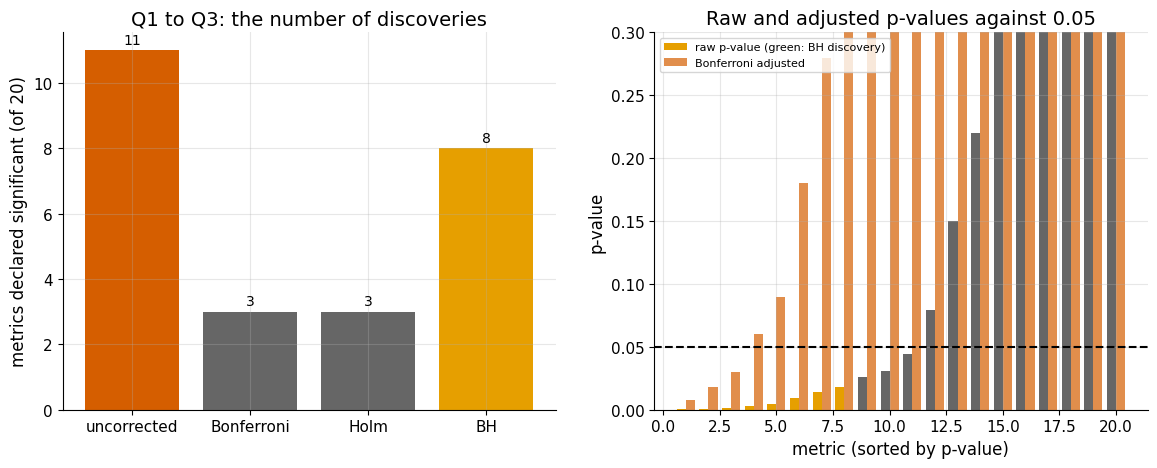

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.9))
labels = ["uncorrected", "Bonferroni", "Holm", "BH"]; counts = [(pvals <= 0.05).sum(), bonf_rej, holm_rej, bh_rej]
axes[0].bar(labels, counts, color=[HIGHLIGHT, NEUTRAL, NEUTRAL, SIM]); axes[0].set_ylabel("metrics declared significant (of 20)"); axes[0].set_title("Q1 to Q3: the number of discoveries")
for i_, c_ in enumerate(counts): axes[0].text(i_, c_ + 0.2, str(c_), ha="center")
axes[1].bar(k - 0.2, pvals, 0.4, color=[SIM if q <= 0.05 else NEUTRAL for q in q_bh], label="raw p-value (green: BH discovery)"); axes[1].bar(k + 0.2, np.minimum(1, m * pvals), 0.4, color=HIGHLIGHT, alpha=0.7, label="Bonferroni adjusted"); axes[1].axhline(0.05, color="black", linestyle="--"); axes[1].set_ylim(0, 0.3)
axes[1].set_xlabel("metric (sorted by p-value)"); axes[1].set_ylabel("p-value"); axes[1].set_title("Raw and adjusted p-values against 0.05"); axes[1].legend(fontsize=8)
plt.show()

### 11.5 Interpretation and decision (Example 1)
- Without correction **11 of 20** metrics look significant. Bonferroni and Holm keep **3** and Benjamini-Hochberg keeps **8**. The BH adjusted p-value of the eighth metric is $20(0.018)/8=0.045$.
- In the simulated dashboards (5 truly affected metrics out of 20), the uncorrected rule makes at least one false claim in **54 %** of dashboards (0.75 false metrics per dashboard) and its false discovery share is 12 %. Bonferroni keeps the chance of any false claim at **3.5 %** but finds only 3.3 of the 5 real effects; Holm finds slightly more (3.35); BH finds **4.1** of 5 with a false discovery share of **3.8 %**, below 5 %, although it makes at least one false claim in 18 % of dashboards (that is the FDR trade-off, not an error).
- **Decision.** Name one primary metric before the test and test it at 5 % without correction. For the other 19, report the BH-adjusted list (8 metrics) as "findings to follow up", and use Holm if a single false claim would be costly (a launch decision). Never present the 11 raw "significant" metrics as results.

---
### Example 2: screening 2,000 features (FDR in a machine-learning pipeline)

**Scenario.** A data scientist tests each of **2,000 candidate features** for association with an outcome. In truth **100** features matter (a $z$-shift of 3.5) and 1,900 are pure noise. The candidates are then examined in detail.

**Questions**
1. How many features pass at $p<0.05$ without correction, and what share of them are false?
2. What do Bonferroni and Benjamini-Hochberg give (discoveries, false discoveries, power)?
3. Which procedure suits a screening step whose output is followed up?

### 11.6 By hand
**Q1.** Expected false positives $=1900\times0.05=95$. Expected true positives with a $z$-shift of 3.5: $P(Z>1.645-3.5)=P(Z>-1.855)=0.968$, so about 97. About **192 discoveries, of which 95 (49 %) are false**.

**Q2.** Bonferroni threshold $0.05/2000=2.5\times10^{-5}$ ($z>4.06$): power $P(Z>4.06-3.5)=0.29$: about 29 true discoveries and (almost) no false ones. BH keeps the false share near $\frac{1900}{2000}0.05=4.75\,\%$ and finds many more.

                    discoveries  false  false share  power
rule                                                      
uncorrected                 174     77        0.443   0.97
Bonferroni                   27      0        0.000   0.27
Benjamini-Hochberg           77      5        0.065   0.72
BH over 300 repetitions: average false share 0.0477 (theory <= 0.0475), average power 0.724


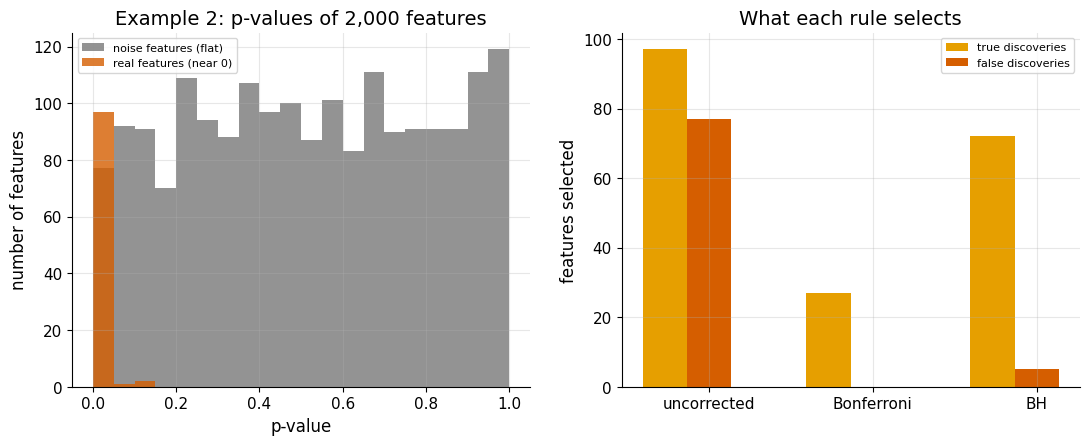

In [16]:
g2 = np.random.default_rng(2); z2 = g2.normal(size=2000); z2[:100] += 3.5; p2 = stats.norm.sf(z2)
def summary(rej, name):
    V, S = rej[100:].sum(), rej[:100].sum(); return {"rule": name, "discoveries": int(V + S), "false": int(V), "false share": V / max(V + S, 1), "power": S / 100}
tab2 = pd.DataFrame([summary(p2 <= 0.05, "uncorrected"), summary(p2 <= 0.05 / 2000, "Bonferroni"), summary(stats.false_discovery_control(p2) <= 0.05, "Benjamini-Hochberg")]).set_index("rule")
print(tab2.round(3).to_string())
assert tab2.loc["uncorrected", "false share"] > 0.35 and tab2.loc["Bonferroni", "false"] <= 1 and tab2.loc["Benjamini-Hochberg", "false share"] < 0.12 and tab2.loc["Benjamini-Hochberg", "power"] > tab2.loc["Bonferroni", "power"] + 0.2
reps2 = [summary(stats.false_discovery_control(stats.norm.sf(np.concatenate([g2.normal(3.5, 1, 100), g2.normal(size=1900)]))) <= 0.05, "bh") for _ in range(300)]
print(f"BH over 300 repetitions: average false share {np.mean([r['false share'] for r in reps2]):.4f} (theory <= 0.0475), average power {np.mean([r['power'] for r in reps2]):.3f}")
assert np.mean([r["false share"] for r in reps2]) < 0.055
fig, axes = plt.subplots(1, 2, figsize=(13, 4.6))
axes[0].hist(p2[100:], bins=20, range=(0, 1), color=NEUTRAL, alpha=0.7, label="noise features (flat)"); axes[0].hist(p2[:100], bins=20, range=(0, 1), color=HIGHLIGHT, alpha=0.8, label="real features (near 0)"); axes[0].set_xlabel("p-value"); axes[0].set_ylabel("number of features"); axes[0].set_title("Example 2: p-values of 2,000 features"); axes[0].legend(fontsize=8)
w = 0.27; xx = np.arange(3); axes[1].bar(xx - w, tab2["discoveries"] - tab2["false"], w, color=SIM, label="true discoveries"); axes[1].bar(xx, tab2["false"], w, color=HIGHLIGHT, label="false discoveries"); axes[1].set_xticks(xx); axes[1].set_xticklabels(["uncorrected", "Bonferroni", "BH"]); axes[1].set_ylabel("features selected"); axes[1].set_title("What each rule selects"); axes[1].legend(fontsize=8)
plt.show()

### 11.7 Interpretation and decision (Example 2)
- Without correction 174 of the 2,000 features pass, and **77 of them (44 %) are noise**. Bonferroni returns 27 features, none false, but finds only **27 % of the 100 real features**. Benjamini-Hochberg returns 77 features of which 5 are false (6.5 % in this draw), and finds **72 %** of the real ones.
- Over 300 repetitions the average BH false share is **0.0477**, matching the theoretical $\frac{1900}{2000}\times0.05=0.0475$ almost exactly: the guarantee is on the *average* share, so single runs vary around it.
- **Decision.** For screening, where the survivors go on to a second check, use **BH at 5 %** (or even 10 %): it keeps the follow-up list mostly real and loses far fewer true features than Bonferroni. Use Bonferroni only when each selected feature will be acted on without confirmation.

---
### Example 3: four page variants (Tukey's HSD after ANOVA)

**Scenario.** Four page variants A, B, C, D have true mean revenue per visitor 10.0, 10.4, 11.2 and 12.0 dollars (SD 2.5), with **40 visitors each**. All $\binom42=6$ pairwise differences are of interest.

**Questions**
1. What are the p-values of the six pairwise comparisons from Tukey's HSD, and from unadjusted $t$-tests?
2. Under the *null* (all four equal), how often does at least one unadjusted pairwise test come out significant, compared with Tukey?

### 11.8 By hand
**Q1.** Tukey's critical difference is $q_{0.05;4,156}\,s/\sqrt n=3.67\times2.5/\sqrt{40}=1.45$ dollars (with $s\approx2.5$), against the unadjusted $t$ threshold $1.975\times2.5\sqrt{2/40}=1.10$: pairs must differ by 1.45 rather than 1.10 to be called significant after the correction. The p-values are computed below.

**Q2.** Six pairwise comparisons: for independent tests $1-0.95^6=26\,\%$; the pairwise $t$-tests share data, so the exact value is a little lower (about 20 %, by simulation).

       difference  unadjusted p  Tukey p  Bonferroni p
pair                                                  
B - A      0.6815        0.1490   0.5485        0.8942
C - A      1.6843        0.0007   0.0071        0.0045
D - A      3.1441        0.0000   0.0000        0.0000
C - B      1.0028        0.0445   0.2119        0.2673
D - B      2.4626        0.0000   0.0000        0.0001
D - C      1.4598        0.0106   0.0262        0.0634
significant at 5 %: unadjusted 5, Tukey 4, Bonferroni 3


under the null: P(at least one significant pairwise test): unadjusted 0.200, Tukey 0.049


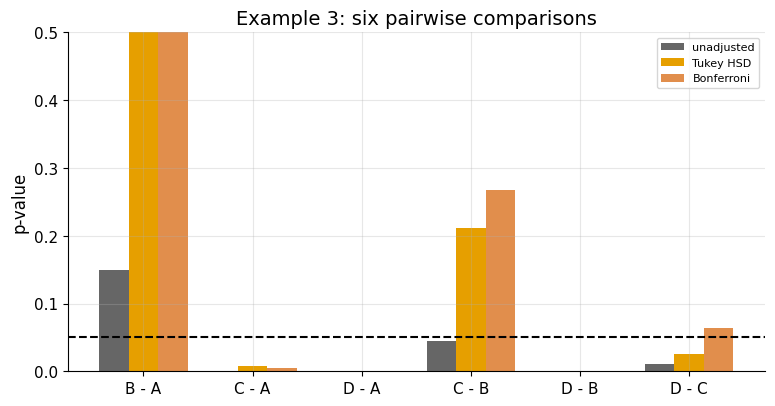

In [17]:
d4 = [np.random.default_rng(10 + i).normal(m_, 2.5, 40) for i, m_ in enumerate([10.0, 10.4, 11.2, 12.0])]
tk4 = stats.tukey_hsd(*d4); names = "ABCD"; rows = []
for i, j in itertools.combinations(range(4), 2):
    rows.append({"pair": f"{names[j]} - {names[i]}", "difference": d4[j].mean() - d4[i].mean(), "unadjusted p": stats.ttest_ind(d4[j], d4[i]).pvalue, "Tukey p": tk4.pvalue[i, j], "Bonferroni p": min(1, 6 * stats.ttest_ind(d4[j], d4[i]).pvalue)})
tab4 = pd.DataFrame(rows).set_index("pair"); print(tab4.round(4).to_string())
print(f"significant at 5 %: unadjusted {int((tab4['unadjusted p'] < 0.05).sum())}, Tukey {int((tab4['Tukey p'] < 0.05).sum())}, Bonferroni {int((tab4['Bonferroni p'] < 0.05).sum())}")
g4 = np.random.default_rng(8); reps4 = 20000; D = g4.normal(0, 2.5, (reps4, 4, 40)); mu = D.mean(axis=2); sp2 = D.var(axis=2, ddof=1).mean(axis=1)
pr = list(itertools.combinations(range(4), 2)); dif = np.abs(np.stack([mu[:, j] - mu[:, i] for i, j in pr], axis=1)); se_ = np.sqrt(sp2 * 2 / 40)[:, None]
un_ = ((dif / se_) > stats.t.ppf(0.975, 156)).any(axis=1).mean(); tk_ = ((dif / (se_ / np.sqrt(2))) > stats.studentized_range.ppf(0.95, 4, 156)).any(axis=1).mean(); un, tk = un_ * reps4, tk_ * reps4
print(f"under the null: P(at least one significant pairwise test): unadjusted {un / reps4:.3f}, Tukey {tk / reps4:.3f}")
assert un / reps4 > 0.15 and abs(tk / reps4 - 0.05) < 0.02 and (tab4["Tukey p"] >= tab4["unadjusted p"] - 1e-6).all()
fig, ax = plt.subplots(figsize=(9, 4.4)); xx = np.arange(6)
ax.bar(xx - 0.27, tab4["unadjusted p"], 0.27, color=NEUTRAL, label="unadjusted"); ax.bar(xx, tab4["Tukey p"], 0.27, color=SIM, label="Tukey HSD"); ax.bar(xx + 0.27, tab4["Bonferroni p"], 0.27, color=HIGHLIGHT, alpha=0.7, label="Bonferroni")
ax.axhline(0.05, color="black", linestyle="--"); ax.set_xticks(xx); ax.set_xticklabels(tab4.index); ax.set_ylabel("p-value"); ax.set_ylim(0, 0.5); ax.set_title("Example 3: six pairwise comparisons"); ax.legend(fontsize=8)
plt.show()

### 11.9 Interpretation and decision (Example 3)
- Unadjusted pairwise $t$-tests flag **5** of the 6 pairs, Bonferroni **3**, Tukey HSD **4**. The pair C - B (p = 0.045 unadjusted) becomes **0.21** after Tukey, and D - C goes from 0.011 to 0.026. Tukey is less conservative than Bonferroni here (D - C survives Tukey but not Bonferroni), because it uses the exact distribution of the largest difference.
- When all four variants are truly equal, the unadjusted pairwise tests find a "significant" pair in **20 %** of experiments (not 26 %, because the six tests share data); Tukey keeps it at **4.9 %**.
- **Decision.** After an ANOVA use Tukey HSD for all pairs. Here D is clearly better than A and B, and probably better than C (p = 0.026); the apparent difference between B and C does not survive the correction and should not be reported.

## 12. Where it is used

### Statistics
- **Genomics and neuroimaging** (tens of thousands of simultaneous tests, FDR control), **clinical trials** with several endpoints or arms (Holm, gatekeeping), **post-hoc comparisons** after ANOVA (Tukey, Dunnett), **subgroup analyses** (which are exploratory unless pre-specified).
- **The replication crisis:** many failed replications trace to uncorrected multiple comparisons and flexible analyses.

### Data science
- **A/B testing platforms** with dozens of metrics and segments; **monitoring** of many features for drift (one KS test per feature, 06_05); search over many experiments (the "winner's curse").
- **Automated analysis and "insight" tools** that scan thousands of slices of a dataset must report FDR-adjusted findings or they will mostly report noise.

### ML and AI
- **Feature selection** by univariate screening (Example 2), **comparing many models or hyperparameters on one test set** (the maximum of $K$ noisy scores is biased; use a held-out set or a correction), and checking **fairness metrics across many subgroups**.
- **Multiple comparisons in benchmarks:** claiming "state of the art" on one of 30 tasks by luck; the Holm-corrected Wilcoxon or Friedman-Nemenyi procedure compares many algorithms over many datasets.

## 13. Common pitfalls and misconceptions

- **"We only looked at the significant ones, so there is no multiplicity"**: the number of tests that *could* have been run (the forking paths) counts, not just those reported.
- **Correcting too late or not at all:** decide the family of tests (and the correction) before looking at the data.
- **Applying Bonferroni to hundreds of correlated tests** is extremely conservative; FDR methods or permutation-based thresholds (max-statistic) do better.
- **FDR is not "5 % of the hypotheses are false":** it is the expected share of false *discoveries* among those declared; with few discoveries the realised share can be 0 or 100 %.
- **BH assumes independence or positive dependence;** for arbitrary dependence use Benjamini-Yekutieli (less power).
- **Corrected p-values are not probabilities of being true;** they are the smallest level at which the hypothesis would still be rejected.
- **Not every analysis needs correction:** one pre-specified primary test needs none, and secondary tests can be hierarchical.
- **Winner's curse:** the effect size of a discovery selected out of many is biased upward; confirm on new data.

## 14. Exercises

1. Eight p-values are 0.001, 0.008, 0.012, 0.025, 0.038, 0.12, 0.45, 0.78. Apply Bonferroni, Holm and Benjamini-Hochberg at 5 % and list the adjusted p-values.
2. For $m=30$ independent true null tests at $\alpha=0.05$ compute the FWER without correction, the Bonferroni threshold and the Sidak threshold.
3. 5,000 genes are tested; 4,500 are null. How many false positives are expected at $p<0.01$ without correction? What FDR does that imply if 400 of the 500 non-null genes are detected?
4. Show by simulation that Holm rejects at least as many hypotheses as Bonferroni in every run (take 500 datasets of 50 tests).
5. A model is chosen as the best of 20 candidates on a validation set of 1,000 examples (all equally accurate, true accuracy 0.8). By simulation, how much is the best validation accuracy above 0.8 on average? What does this say about reporting it?
6. (Harder) Compare the power of Bonferroni and Benjamini-Hochberg as the share of real effects grows from 1 % to 50 % (500 tests, effect 3): at what share does BH overtake?

Solutions are at the end.

## 15. Summary table

| Method | Controls | Rule | Strength | Caveat |
|---|---|---|---|---|
| Bonferroni | FWER | $p\le\alpha/m$ | simple, any dependence | conservative |
| Sidak | FWER | $p\le1-(1-\alpha)^{1/m}$ | slightly sharper | independence |
| Holm | FWER | step-down $\alpha/(m-k+1)$ | better than Bonferroni | still strict |
| Benjamini-Hochberg | FDR | step-up $k\alpha/m$ | high power | independence / positive dependence |
| Benjamini-Yekutieli | FDR | BH with $\alpha/\sum1/k$ | any dependence | lower power |
| Tukey HSD | FWER (pairs) | studentised range | after ANOVA | equal variances |
| `scipy` | `false_discovery_control`, `tukey_hsd` | | | |

## Solutions

In [18]:
p1 = np.array([0.001, 0.008, 0.012, 0.025, 0.038, 0.12, 0.45, 0.78]); m1 = p1.size
bonf = np.minimum(1, m1 * p1); holm_adj = np.minimum(1, np.maximum.accumulate((m1 - np.arange(m1)) * p1)); bh_adj = stats.false_discovery_control(p1)
print("1: Bonferroni adjusted", np.round(bonf, 3), "-> rejects", int((bonf <= 0.05).sum()), "| Holm adjusted", np.round(holm_adj, 3), "-> rejects", int((holm_adj <= 0.05).sum()), "| BH adjusted", np.round(bh_adj, 3), "-> rejects", int((bh_adj <= 0.05).sum()))
print(f"2: FWER = {1 - 0.95 ** 30:.3f}, Bonferroni threshold = {0.05 / 30:.5f}, Sidak threshold = {1 - 0.95 ** (1 / 30):.5f}")
fp3 = 4500 * 0.01; print(f"3: expected false positives = {fp3:.0f}; discoveries = {fp3 + 400:.0f}; false share = {fp3 / (fp3 + 400):.3f}")
g4s = np.random.default_rng(4); diffs = 0
for _ in range(500):
    p_ = g4s.uniform(size=50) ** 1.6; diffs += int(r_holm(p_, 0.05).sum()) - int(r_bonf(p_, 0.05).sum()) < 0
print(f"4: runs in which Holm rejected fewer than Bonferroni: {diffs} of 500 (Holm is never worse)")
g5 = np.random.default_rng(5); best = g5.binomial(1000, 0.8, (5000, 20)).max(axis=1) / 1000; print(f"5: average best validation accuracy of 20 equal models: {best.mean():.4f} (true accuracy 0.80): an upward bias of {best.mean() - 0.8:.4f}")
rows6 = []
for fr_ in (0.01, 0.05, 0.1, 0.2, 0.3, 0.5):
    fd_b, pw_b, _ = simulate(r_bonf, m=500, m1=max(1, int(500 * fr_)), shift=3.0, reps=150, seed=int(fr_ * 100)); fd_h, pw_h, _ = simulate(r_bh, m=500, m1=max(1, int(500 * fr_)), shift=3.0, reps=150, seed=int(fr_ * 100)); rows6.append((fr_, round(pw_b, 3), round(pw_h, 3)))
print("6: share of real effects, power of Bonferroni, power of BH:", rows6)
assert int((bh_adj <= 0.05).sum()) >= int((holm_adj <= 0.05).sum()) >= int((bonf <= 0.05).sum()) and diffs == 0 and best.mean() > 0.81

1: Bonferroni adjusted [0.008 0.064 0.096 0.2   0.304 0.96  1.    1.   ] -> rejects 1 | Holm adjusted [0.008 0.056 0.072 0.125 0.152 0.36  0.9   0.9  ] -> rejects 1 | BH adjusted [0.008 0.032 0.032 0.05  0.061 0.16  0.514 0.78 ] -> rejects 4
2: FWER = 0.785, Bonferroni threshold = 0.00167, Sidak threshold = 0.00171
3: expected false positives = 45; discoveries = 445; false share = 0.101
4: runs in which Holm rejected fewer than Bonferroni: 0 of 500 (Holm is never worse)
5: average best validation accuracy of 20 equal models: 0.8233 (true accuracy 0.80): an upward bias of 0.0233


6: share of real effects, power of Bonferroni, power of BH: [(0.01, np.float64(0.255), np.float64(0.347)), (0.05, np.float64(0.244), np.float64(0.512)), (0.1, np.float64(0.234), np.float64(0.62)), (0.2, np.float64(0.229), np.float64(0.709)), (0.3, np.float64(0.237), np.float64(0.772)), (0.5, np.float64(0.238), np.float64(0.836))]


**1.** Bonferroni adjusted p-values $0.008,\,0.064,\,0.096,\dots$: **1** rejection. Holm adjusted $0.008,\,0.056,\,0.072,\dots$: **1** rejection. BH adjusted $0.008,\,0.032,\,0.032,\,0.050,\,0.061,\dots$: **4** rejections (the fourth has an adjusted p-value of exactly 0.05). Uncorrected, 5 would be rejected.

**2.** FWER $=1-0.95^{30}=0.785$; Bonferroni threshold $0.05/30=0.00167$; Sidak $1-0.95^{1/30}=0.00171$ (almost identical).

**3.** Expected false positives $=4500\times0.01=45$; discoveries about $45+400=445$, so a false discovery share of $45/445=$ **10.1 %**, double the 5 % one might assume.

**4.** In 500 runs Holm never rejected fewer hypotheses than Bonferroni (0 of 500): Holm uniformly dominates.

**5.** The best of 20 equally accurate models scores on average **0.823** on the validation set against a true 0.80: an upward bias of 2.3 points. The winner's score must be confirmed on fresh data, never reported as is.

**6.** Power (500 tests, effect 3): Bonferroni stays near 0.23 to 0.26 at every share of real effects, while BH rises from 0.35 (1 % real) to 0.51 (5 %), 0.62 (10 %), 0.71 (20 %), 0.77 (30 %) and 0.84 (50 %). BH is more powerful already at 1 % real effects and the gap widens with the share, because the BH threshold $k\alpha/m$ grows with the number of discoveries.